# TP 3 — Apprentissage supervise 2A (correction R)

**Objectif du sujet.** Travailler avec les **arbres CART** et les **forets aleatoires**. On reprend le jeu de
donnees « vins » du TP2, mais cette fois on predit la **note reelle** (`quality`) : c'est un probleme de
**regression**.

> Correction en **R** avec `rpart` (CART), `ranger`/`caret` (forets) et **plotly**. Un avantage de `rpart` :
> il fournit **nativement** les splits **concurrents** et de **substitution (surrogate)** demandes a la
> question 2.b — ce que scikit-learn n'implemente pas.


## Brief de demarrage — Les outils de ce TP

> **A lire avant de commencer.** Ce TP passe des modeles « a frontiere » (TP2) aux methodes **a base d'arbres**.
> On predit ici la **note reelle** du vin (regression). Voici comment fonctionnent les deux outils. Des
> **graphiques explicatifs** illustrent chaque idee dans l'**annexe** en fin de notebook.

**1. Arbre CART — une suite de questions oui/non.**
Un arbre partitionne l'espace des variables en **rectangles** (les feuilles). A chaque noeud, il cherche la
**variable** et le **seuil** qui separent le mieux les donnees : en regression, on choisit la coupure qui
**minimise la variance** des $y$ dans les deux sous-groupes. La prediction d'une feuille est la **moyenne** des
$y$ qu'elle contient.
- ✅ **interpretable** (on lit les regles), gere non-linearites et interactions ;
- ❌ **instable** : un leger changement des donnees peut modifier tout l'arbre ⇒ **variance elevee**. Un arbre
  profond **surajuste** (il « apprend le bruit »). On limite donc sa profondeur / on l'elague (parametre `cp`).

**2. Foret aleatoire — moyenner beaucoup d'arbres pour reduire la variance.**
Une foret combine deux ingredients d'**alea** pour rendre les arbres *differents les uns des autres*, puis
**moyenne** leurs predictions :
1. **Bagging** (*bootstrap aggregating*) : chaque arbre est entraine sur un **echantillon bootstrap** (tirage
   avec remise) du jeu d'apprentissage ;
2. **Sous-echantillonnage des variables** : a chaque coupure, seul un **sous-ensemble aleatoire** de variables
   est candidat (`mtry`).

Comme les arbres sont peu correles, **la moyenne reduit fortement la variance** sans trop augmenter le biais :
la foret est bien plus **stable** et **precise** que l'arbre seul. Bonus : les points non tires par le bootstrap
(**out-of-bag**) fournissent une estimation « gratuite » de l'erreur de test.

| Aspect | Arbre CART | Foret aleatoire |
|---|---|---|
| Biais | faible | faible |
| Variance | **elevee** | **reduite** (moyennage) |
| Interpretabilite | **forte** | plus faible (importances) |
| Hyperparametres cles | profondeur, `cp` | `num.trees`, `mtry`, profondeur |

> **Methode du TP.** (1) EDA ; (2) entrainer un **arbre CART** et regler sa complexite ; (3) entrainer une
> **foret** et regler ses hyperparametres ; (4) **comparer** (RMSE, erreur OOB) et interpreter les
> **importances de variables**.

In [ ]:
source(if (file.exists("plot_theme.R")) "plot_theme.R" else "../plot_theme.R")  # theme + charger_packages()
charger_packages(c(
                   "rpart",
                   "rpart.plot",
                   "ranger",
                   "caret",
                   "plotly"
))

SEED <- 0
set.seed(SEED)   # graine unique posee une fois : tout le TP est reproductible

## Partie 1 — Chargement et analyse exploratoire

### Rappel de cours — Arbres CART (regression)

Un **arbre CART** partitionne recursivement l'espace des variables en regions. A chaque noeud, il choisit la
**variable** et le **seuil** qui **minimisent l'impurete** ; en regression, l'impurete est la **variance**
(erreur quadratique) des $y$ dans le noeud. La prediction d'une feuille est la **moyenne** des $y$ qu'elle
contient. Avantages : interpretable, gere non-linearites et interactions ; inconvenient : **instable** (forte
variance) — d'ou les forets.

### Question 1 — Chargement et analyse exploratoire


In [ ]:

url <- "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine <- read.csv(url, sep = ";")
y <- wine$quality                              # note reelle : probleme de REGRESSION
X <- wine[, setdiff(names(wine), "quality")]

cat("Dimensions :", dim(X), "| cible y = note (regression)\n\n")
print(round(t(sapply(X, summary)), 2))


Dimensions : 1599 11 | cible y = note (regression)



                     Min. 1st Qu. Median  Mean 3rd Qu.   Max.
fixed.acidity        4.60    7.10   7.90  8.32    9.20  15.90
volatile.acidity     0.12    0.39   0.52  0.53    0.64   1.58
citric.acid          0.00    0.09   0.26  0.27    0.42   1.00
residual.sugar       0.90    1.90   2.20  2.54    2.60  15.50
chlorides            0.01    0.07   0.08  0.09    0.09   0.61
free.sulfur.dioxide  1.00    7.00  14.00 15.87   21.00  72.00
total.sulfur.dioxide 6.00   22.00  38.00 46.47   62.00 289.00
density              0.99    1.00   1.00  1.00    1.00   1.00
pH                   2.74    3.21   3.31  3.31    3.40   4.01
sulphates            0.33    0.55   0.62  0.66    0.73   2.00
alcohol              8.40    9.50  10.20 10.42   11.10  14.90


In [ ]:

qc <- as.data.frame(table(y)); names(qc) <- c("Note", "Effectif")
plot_ly(qc, x = ~Note, y = ~Effectif, type = "bar",
        text = ~Effectif, textposition = "outside",
        marker = list(color = pick_color(2))) %>%
  layout(title = "Distribution de la note du vin (quality)",
         xaxis = list(title = "Note"), yaxis = list(title = "Effectif")) %>%
  apply_dark_theme()


HTML widgets cannot be represented in plain text (need html)

### Question 2 — Exploration visuelle : variables influencant la qualite

In [ ]:
# Correlation de Spearman (rangs) : adaptee a une note ordinale
corr <- sort(sapply(X, function(col) cor(col, y, method = "spearman")))
cdf <- data.frame(variable = factor(names(corr), levels = names(corr)), correlation = as.numeric(corr))
cdf$signe <- ifelse(cdf$correlation >= 0, "positive", "negative")
plot_ly(cdf, x = ~correlation, y = ~variable, type = "bar", orientation = "h",
        color = ~signe, colors = c(negative = pick_color(1), positive = pick_color(0))) %>%
  layout(title = "Correlation de chaque variable avec la note",
         xaxis = list(title = "Correlation de Spearman"), yaxis = list(title = "")) %>%
  apply_dark_theme()

HTML widgets cannot be represented in plain text (need html)

**Ce que l'on remarque :** comme au TP2, **`alcohol`** est la variable la plus correlee (positivement) a la
note, suivie de **`sulphates`** et **`citric.acid`** ; **`volatile.acidity`** est correlee **negativement**.
La note est concentree sur 5 et 6 (peu de vins tres bons ou tres mauvais).


## Partie 2 — Decoupage et entrainement

### Question 1 — Construction des jeux d'apprentissage et de test


In [ ]:
idx <- createDataPartition(y, p = 0.75, list = FALSE)
Xtr <- X[idx, ]; Xte <- X[-idx, ]
ytr <- y[idx];   yte <- y[-idx]
dtr <- cbind(Xtr, quality = ytr)
cat("Apprentissage :", nrow(Xtr), "| Test :", nrow(Xte), "\n")

Apprentissage : 1200 | Test : 399 


### Question 2 — Algorithme CART

**2.a** On entraine un arbre CART en limitant la profondeur (`maxdepth = 3`) pour obtenir un arbre **lisible**.


In [ ]:

# maxdepth = 3 pour obtenir un arbre lisible et interpretable
arbre <- rpart(quality ~ ., data = dtr, method = "anova",
               control = rpart.control(maxdepth = 3, cp = 0, xval = 0))
racine <- as.character(arbre$frame$var[1])
cat("Split de la RACINE : variable =", racine, "\n")


Split de la RACINE : variable = alcohol 


**2.b — Splits concurrents (*competing*) et de substitution (*surrogate*) a la racine.**

- Un **split concurrent** est une *autre* variable qui aurait presque aussi bien reduit l'impurete a ce noeud.
- Un **split de substitution (surrogate)** sert a **gerer les valeurs manquantes** : si la variable du split
  principal est manquante, l'arbre utilise une variable de substitution qui **envoie les individus du meme
  cote** que le split principal (elle « imite » au mieux la decision principale).

`rpart` les affiche directement dans `summary()` (`Primary splits` et `Surrogate splits`).


In [ ]:

# rpart fournit NATIVEMENT les splits concurrents (Primary) et de substitution (Surrogate)
s <- capture.output(summary(arbre))
# On affiche le detail du noeud racine (Node number 1)
i0 <- grep("Node number 1:", s)[1]
cat(paste(s[i0:(i0 + 17)], collapse = "\n"), "\n")


Node number 1: 1200 observations,    complexity param=0.186779
  mean=5.634167, MSE=0.6519993 
  left son=2 (746 obs) right son=3 (454 obs)
  Primary splits:
      alcohol          < 10.525   to the left,  improve=0.18677900, (0 missing)
      sulphates        < 0.645    to the left,  improve=0.12379370, (0 missing)
      volatile.acidity < 0.375    to the right, improve=0.11588300, (0 missing)
      citric.acid      < 0.295    to the left,  improve=0.06651209, (0 missing)
      density          < 0.995565 to the right, improve=0.06418744, (0 missing)
  Surrogate splits:
      density              < 0.995575 to the right, agree=0.774, adj=0.403, (0 split)
      chlorides            < 0.0685   to the right, agree=0.706, adj=0.222, (0 split)
      fixed.acidity        < 6.75     to the right, agree=0.667, adj=0.121, (0 split)
      volatile.acidity     < 0.3675   to the right, agree=0.661, adj=0.104, (0 split)
      total.sulfur.dioxide < 17.5     to the right, agree=0.654, adj=0.086, (0

**Reponse a la question 2.b.** Le split principal de la racine porte sur **`alcohol`**. Si, pour un nouveau
vin, **`alcohol` ET `density` sont manquantes**, `rpart` descend la liste des **surrogates** et utilise **la
premiere variable de substitution disponible** qui n'est ni `alcohol` ni `density` : d'apres le tableau
ci-dessus, c'est **`chlorides`** (avec son seuil), qui decide alors de la direction gauche/droite. Si aucune
substitution n'est disponible, `rpart` applique la **regle par defaut** : envoyer l'individu vers le noeud fils
**majoritaire**.

**2.c — Visualisation de l'arbre et prediction « a la main ».**


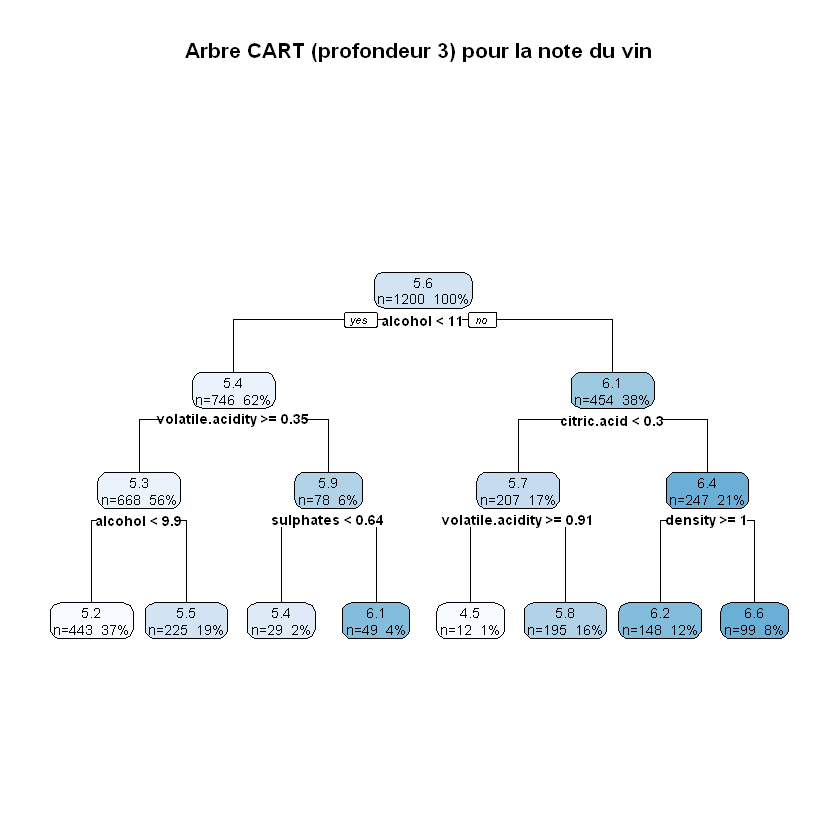

In [ ]:

rpart.plot(arbre, type = 2, extra = 101, box.palette = "Blues",
           main = "Arbre CART (profondeur 3) pour la note du vin")


In [ ]:
# Les valeurs non fournies pour le vin propose prennent la mediane d'apprentissage.
newv <- sapply(Xtr, median)
newv["alcohol"] <- 11.5; newv["pH"] <- 2.0; newv["free.sulfur.dioxide"] <- 7.6
newv["sulphates"] <- 0.42; newv["volatile.acidity"] <- 0.98
newdf <- as.data.frame(as.list(newv))

cat(sprintf("Vin propose (sans note observee) : prediction = %.2f\n", predict(arbre, newdf)))
for (note in c(min(yte), 6, max(yte))) {
    index <- which(yte == note)[1]
    profil <- Xte[index, , drop = FALSE]
    cat(sprintf("Vin de test : note observee = %d | prediction = %.2f\n",
                            yte[index], predict(arbre, profil)))
}
cat("Regles de l'arbre :\n")
print(rpart.rules(arbre))
cat("Une prediction n'est pas forcement la note observee.\n")

Vin propose (sans note observee) : prediction = 4.50


Vin de test : note observee = 3 | prediction = 5.51
Vin de test : note observee = 6 | prediction = 5.20
Vin de test : note observee = 8 | prediction = 6.20


Regles de l'arbre :


 quality                                                                                                                
     4.5 when alcohol >=         10.5 & volatile.acidity >= 0.91 & citric.acid <  0.3                                   
     5.2 when alcohol <   9.9         & volatile.acidity >= 0.35                                                        
     5.4 when alcohol <  10.5         & volatile.acidity <  0.35                      & sulphates <  0.64               
     5.5 when alcohol is  9.9 to 10.5 & volatile.acidity >= 0.35                                                        
     5.8 when alcohol >=         10.5 & volatile.acidity <  0.91 & citric.acid <  0.3                                   
     6.1 when alcohol <  10.5         & volatile.acidity <  0.35                      & sulphates >= 0.64               
     6.2 when alcohol >=         10.5                            & citric.acid >= 0.3                     & density >= 1
     6.6 when alcohol >=        

Une prediction n'est pas forcement la note observee.


On lit la prediction **directement sur le diagramme** en suivant les tests depuis la racine : a chaque noeud,
on compare la valeur du vin au seuil et on part a gauche/droite jusqu'a une feuille dont la valeur est la note
predite. Le split de la racine etant sur `alcohol` (ici $11.5$), le chemin suit les variables affichees.

**2.d — Erreur de generalisation et comparaison vrai / predit.** En regression, on mesure le **RMSE** sur le test.


In [ ]:
pred_arbre <- predict(arbre, Xte)
rmse_cart <- sqrt(mean((pred_arbre - yte)^2))
r2_cart <- 1 - sum((pred_arbre - yte)^2) / sum((yte - mean(yte))^2)
cat(sprintf("Arbre CART : RMSE = %.3f | R2 = %.3f\n", rmse_cart, r2_cart))

jit <- yte + runif(length(yte), -0.15, 0.15)
plot_ly() %>%
  add_trace(x = jit, y = pred_arbre, type = "scatter", mode = "markers",
            opacity = 0.5, name = "Vins",
            marker = list(color = pick_color(0), size = 7)) %>%
  add_trace(x = c(min(yte), max(yte)), y = c(min(yte), max(yte)),
            type = "scatter", mode = "lines", name = "Prediction parfaite",
            line = list(dash = "dash", color = pick_color(2))) %>%
  layout(title = "CART : valeurs reelles vs predites (test)",
         xaxis = list(title = "Note reelle (jitter)"), yaxis = list(title = "Note predite")) %>%
  apply_dark_theme()

Arbre CART : RMSE = 0.705 | R2 = 0.236


HTML widgets cannot be represented in plain text (need html)

**2.e — Robustesse (instabilite) des arbres CART.**

On entraine cinq arbres de profondeur 3 sur cinq sous-echantillons de 50 % des donnees d'apprentissage.
Comparez les **variables et les seuils a tous les noeuds**, ainsi que les valeurs predites par les feuilles :
la racine peut rester `alcohol` alors que son seuil et les regles plus profondes changent. C'est la **structure
complete**, et non seulement la variable a la racine, qui illustre l'instabilite d'un arbre isole. Une foret
attenue cette variance en moyennant de nombreux arbres.

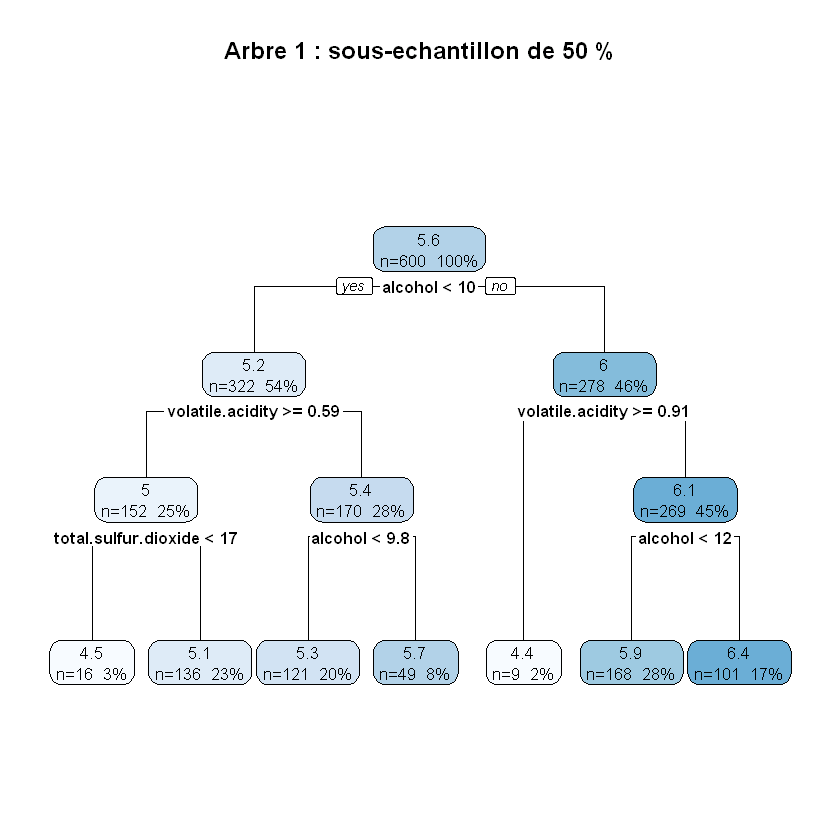

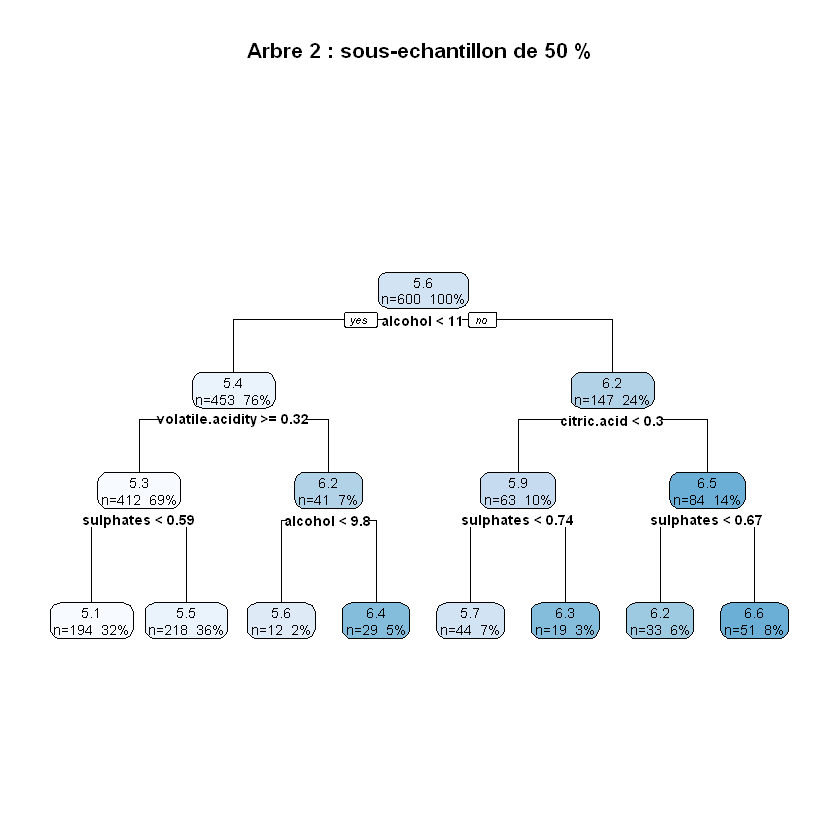

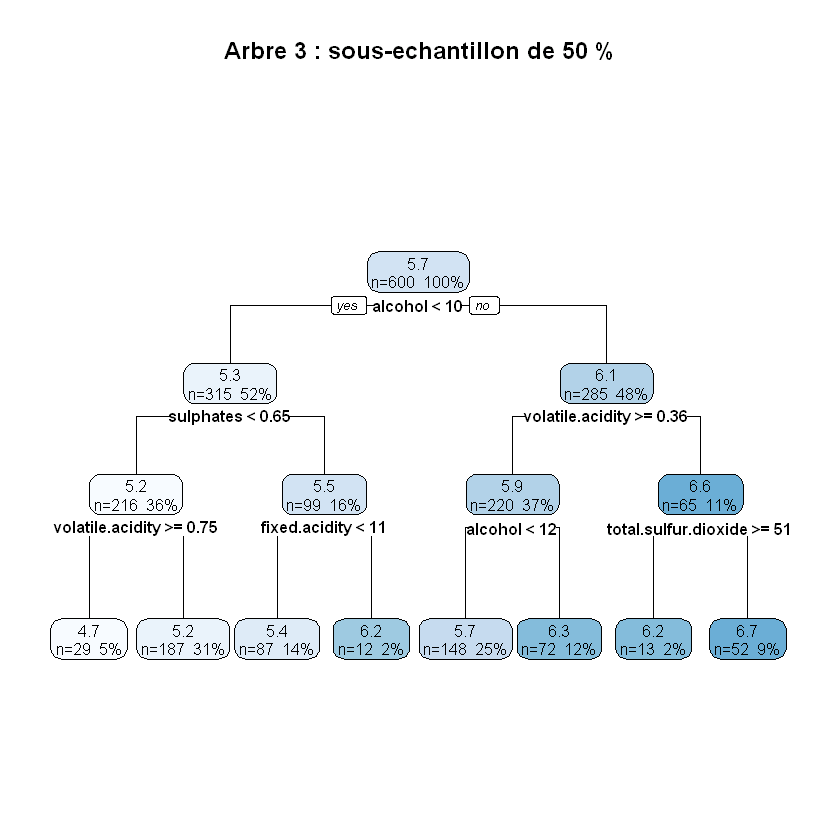

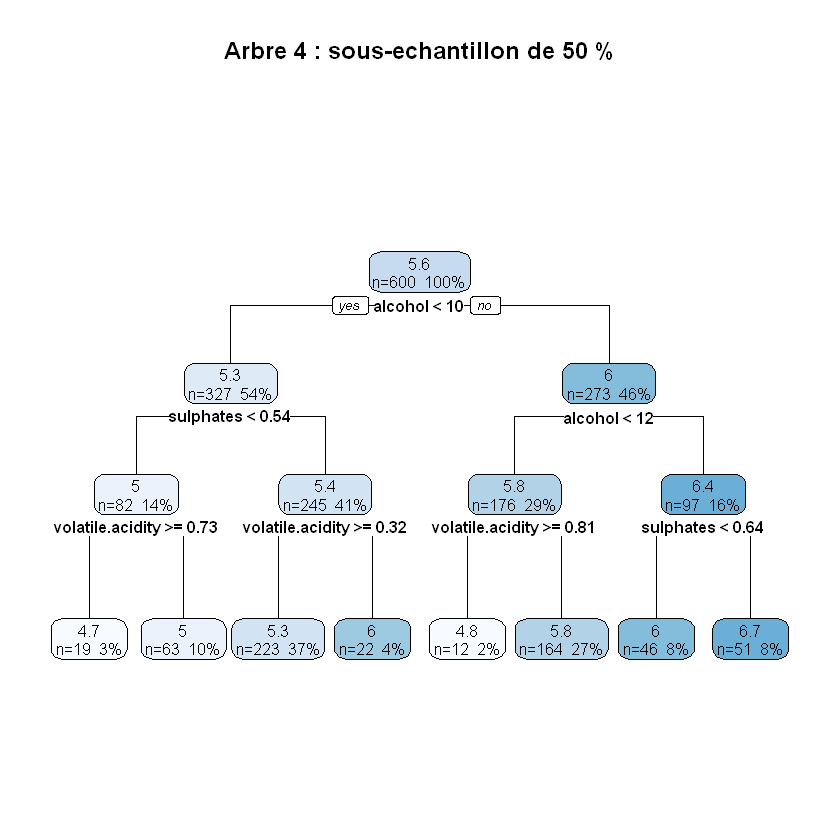

Structures de regles distinctes : 5 sur 5.


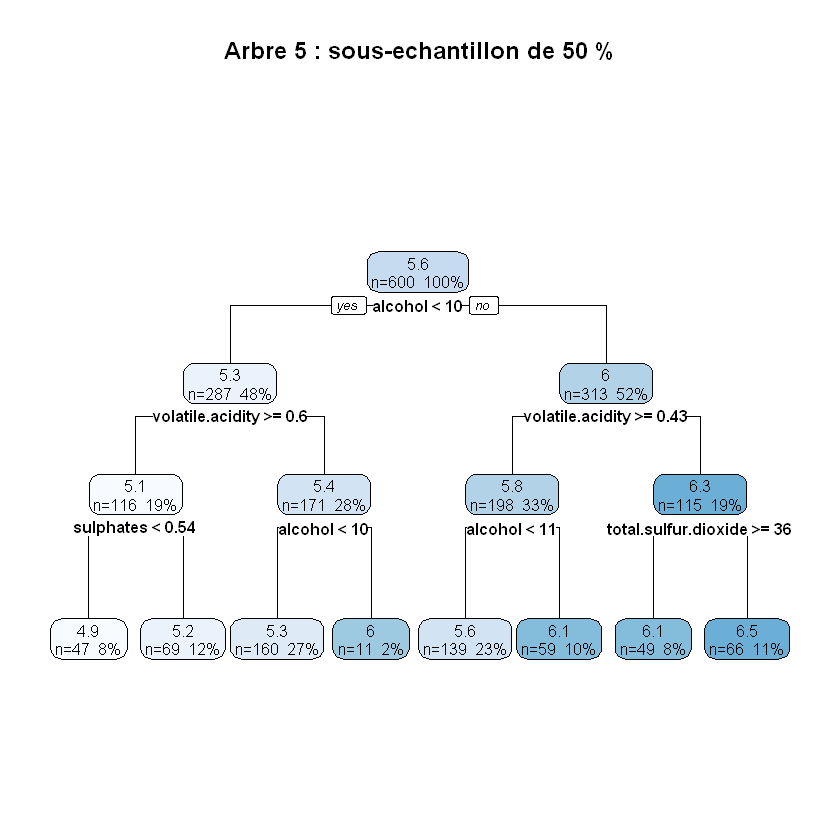

In [ ]:
signatures <- character(5)
for (numero in seq_len(5)) {
  indices <- sample(nrow(Xtr), nrow(Xtr) %/% 2)
  arbre_echantillon <- rpart(quality ~ ., data = dtr[indices, ], method = "anova",
                             control = rpart.control(maxdepth = 3, cp = 0, xval = 0))
  signatures[numero] <- paste(capture.output(rpart.rules(arbre_echantillon)), collapse = "\n")
  rpart.plot(arbre_echantillon, type = 2, extra = 101, box.palette = "Blues",
             main = sprintf("Arbre %d : sous-echantillon de 50 %%", numero))
}
cat(sprintf("Structures de regles distinctes : %d sur 5.\n", length(unique(signatures))))

### Question 3 — Forets aleatoires

### Rappel de cours — Forets aleatoires

Une **foret aleatoire** agrege un grand nombre d'arbres CART entraines sur des **echantillons bootstrap**, en ne
considerant qu'un **sous-ensemble aleatoire de variables** a chaque split (parametre **`mtry`**). Le
**moyennage** reduit fortement la **variance**. Bonus : l'**erreur Out-Of-Bag (OOB)** est une estimation
« gratuite » de l'erreur de generalisation.

**3.a — Hyperparametres reglables** (`ranger`/`caret`) :
- **`mtry`** (nb de variables candidates par split) ;
- **`min.node.size`** (taille minimale des feuilles) ;
- `num.trees` (nombre d'arbres, a prendre « assez grand »).


In [ ]:
# 3.b validation croisee : on fait varier mtry et min.node.size (equivalents ranger/caret)
tg <- expand.grid(mtry = c(3, 4, 6, 8), splitrule = "variance", min.node.size = c(1, 3, 5, 10))
ctrl <- trainControl(method = "cv", number = 5)
rf_fit <- train(Xtr, ytr, method = "ranger", tuneGrid = tg,
                trControl = ctrl, num.trees = 300)
cat("Meilleurs hyperparametres :\n"); print(rf_fit$bestTune)
cat(sprintf("RMSE de validation croisee : %.3f\n", min(rf_fit$results$RMSE)))

Meilleurs hyperparametres :


  mtry splitrule min.node.size
2    3  variance             3


RMSE de validation croisee : 0.595


In [ ]:
res <- rf_fit$results
fig <- plot_ly()
for (taille in sort(unique(res$min.node.size))) {
    groupe <- res[res$min.node.size == taille, ]
    groupe <- groupe[order(groupe$mtry), ]
    fig <- add_trace(fig, data = groupe, x = ~mtry, y = ~RMSE,
                                     type = "scatter", mode = "lines+markers",
                                     name = paste0("min.node.size = ", taille),
                                     hovertemplate = "mtry = %{x}<br>RMSE = %{y:.3f}<extra></extra>")
}
fig %>%
    layout(title = "RMSE en validation croisee selon mtry et la taille minimale des feuilles",
                 xaxis = list(title = "mtry", tickmode = "array", tickvals = c(3, 4, 6, 8)),
                 yaxis = list(title = "RMSE en validation croisee (plus bas = meilleur)")) %>%
    apply_dark_theme()

HTML widgets cannot be represented in plain text (need html)

**3.c & 3.d — Reentrainement optimal, erreur de generalisation et comparaison avec l'OOB.**

In [ ]:
# 3.c reentrainement avec les meilleurs hyperparametres + OOB
best <- rf_fit$bestTune
foret <- ranger(quality ~ ., data = dtr, num.trees = 300,
                mtry = best$mtry, min.node.size = best$min.node.size,
                splitrule = "variance")
pred_foret <- predict(foret, Xte)$predictions
rmse_foret <- sqrt(mean((pred_foret - yte)^2))
rmse_oob   <- sqrt(foret$prediction.error)   # erreur OOB (MSE) fournie par ranger

cat(sprintf("Foret aleatoire : RMSE test = %.3f\n", rmse_foret))
cat(sprintf("RMSE Out-Of-Bag (apprentissage) : %.3f\n", rmse_oob))

jit <- yte + runif(length(yte), -0.15, 0.15)
plot_ly() %>%
  add_trace(x = jit, y = pred_foret, type = "scatter", mode = "markers",
            opacity = 0.5, name = "Vins", marker = list(color = pick_color(3), size = 7)) %>%
  add_trace(x = c(min(yte), max(yte)), y = c(min(yte), max(yte)),
            type = "scatter", mode = "lines", name = "Prediction parfaite",
            line = list(dash = "dash", color = pick_color(2))) %>%
  layout(title = "Foret aleatoire : valeurs reelles vs predites (test)",
         xaxis = list(title = "Note reelle (jitter)"), yaxis = list(title = "Note predite")) %>%
  apply_dark_theme()

Foret aleatoire : RMSE test = 0.566


RMSE Out-Of-Bag (apprentissage) : 0.595


HTML widgets cannot be represented in plain text (need html)

**Comparaison CART vs forêt.** La forêt aléatoire obtient un **RMSE nettement plus faible** que l'arbre CART
de profondeur 3 : le moyennage de centaines d'arbres profonds (faible biais) et peu corrélés réduit la variance
et améliore la généralisation. L'**erreur OOB** est du même ordre que l'erreur de test : elle constitue un bon
substitut « gratuit » à un jeu de validation (chaque arbre est évalué sur les ~37 % d'observations absentes de
son échantillon bootstrap, car $(1 - 1/n)^n \to e^{-1} \approx 0.37$).

On remarque aussi, sur le graphique réel/prédit, que les prédictions sont **tirées vers la moyenne** (les notes
3–4 sont surestimées, les notes 8 sous-estimées) : c'est l'effet classique de la moyenne dans les feuilles quand
les notes extrêmes sont rares.

### Compléments — Importance des variables

Une forêt est moins lisible qu'un arbre, mais on peut mesurer **quelles variables comptent** :
- **MDI** (*Mean Decrease in Impurity*, `feature_importances_`) : réduction de variance cumulée apportée par
  chaque variable dans tous les arbres (calculée sur l'apprentissage, biaisée vers les variables continues à
  nombreux seuils) ;
- **importance par permutation** : dégradation du RMSE **sur le test** quand on mélange aléatoirement une
  variable (on casse son lien avec la cible). Plus fiable pour interpréter.

In [ ]:
# Importance par permutation calculee par ranger sur les observations out-of-bag
foret_imp <- ranger(quality ~ ., data = dtr, num.trees = 300, mtry = best$mtry,
                    min.node.size = best$min.node.size, importance = "permutation")
imp <- sort(ranger::importance(foret_imp))
plot_ly(x = imp, y = factor(names(imp), levels = names(imp)), type = "bar", orientation = "h",
        marker = list(color = pick_color(1))) %>%
  layout(title = "Importance par permutation (hausse du MSE out-of-bag)",
         xaxis = list(title = "Importance"), yaxis = list(title = "")) %>%
  apply_dark_theme(height = 450)

HTML widgets cannot be represented in plain text (need html)

**Lecture.** L'importance par permutation fait ressortir : **`alcohol`**, **`sulphates`** et
**`volatile.acidity`** dominent, ce qui confirme l'analyse exploratoire (corrélations) et la structure de l'arbre
CART (racine sur `alcohol`). Attention : une importance mesure l'**utilité prédictive** d'une variable pour ce
modèle, pas un **effet causal** ; deux variables corrélées peuvent aussi se partager l'importance.

**Question 4 (Bonus) — Visualisation des predictions dans un espace projete 2D (UMAP).**

Le bonus utilise `reticulate` et le package Python `umap-learn`, si disponibles. On normalise les donnees
d'apprentissage, ajuste une projection **supervisee** UMAP en 2D, puis construit une grille 100x100. On
reconstruit approximativement les profils (`inverse_transform`), les de-normalise, et affiche en fond la
prediction de la foret ; les points portent la note observee. En l'absence des dependances, la cellule
affiche un message et le reste du notebook fonctionne normalement.

In [ ]:
if (requireNamespace("reticulate", quietly = TRUE) && reticulate::py_module_available("umap")) {
  reticulate::py_set_seed(SEED)   # la graine R ne controle pas l'alea cote Python
  umap <- reticulate::import("umap")
  minimums <- sapply(Xtr, min)
  amplitudes <- pmax(sapply(Xtr, max) - minimums, .Machine$double.eps)
  normalise   <- function(M) sweep(sweep(as.matrix(M), 2, minimums, "-"), 2, amplitudes, "/")
  denormalise <- function(M) sweep(sweep(M, 2, amplitudes, "*"), 2, minimums, "+")

  reducer <- umap$UMAP(n_components = 2L)
  emb <- reducer$fit_transform(normalise(Xtr), y = as.numeric(ytr))   # projection supervisee

  xs <- seq(min(emb[, 1]), max(emb[, 1]), length.out = 100)
  ys <- seq(min(emb[, 2]), max(emb[, 2]), length.out = 100)
  profils <- denormalise(reducer$inverse_transform(as.matrix(expand.grid(xs, ys))))
  colnames(profils) <- names(Xtr)
  carte <- t(matrix(predict(foret, data = as.data.frame(profils))$predictions, nrow = length(xs)))

  plot_ly() %>%
    add_trace(x = xs, y = ys, z = carte, type = "contour", colorscale = CONTINUOUS_SCALE,
              colorbar = list(title = "Note predite")) %>%
    add_markers(x = emb[, 1], y = emb[, 2], name = "Apprentissage",
                marker = list(color = ytr, colorscale = CONTINUOUS_SCALE, size = 6, showscale = FALSE)) %>%
    layout(title = "Predictions de la foret dans l'espace UMAP 2D",
           xaxis = list(title = "UMAP 1"), yaxis = list(title = "UMAP 2")) %>%
    apply_dark_theme()
} else {
  cat("Bonus non execute : necessite 'reticulate' (R) + 'umap-learn' (Python).\n")
}

Bonus non execute : necessite 'reticulate' (R) + 'umap-learn' (Python).


## Annexe — Les entropies du cours et les coupures CART

**Quel critere pour quel probleme ?** Dans ce TP, `quality` est une note numerique : l'arbre de regression
reduit la **variance** $s^2(t)$. Les entropies du cours (lecon 4, « Trees and Random Forests »,
pages 11-13 du cours, 9-11 du PDF)
decrivent au contraire l'impurete d'un noeud de **classification**. L'exemple ci-dessous classe les vins selon
`quality >= 6` uniquement pour les illustrer.

Dans un noeud $t$, $p_1,\ldots,p_M$ sont les proportions des $M$ classes (avec $0\log 0=0$). Une impurete est
nulle si tous les vins ont la meme classe ; elle est maximale lorsque les classes sont equiprobables :

| Notion du cours | Formule | Interpretation |
|---|---|---|
| Entropie de Shannon | $H_1(t)=-\sum_{k=1}^{M}p_k\ln p_k$ | Mesure l'incertitude sur la classe ; limite $q\to1$ de Tsallis. |
| Entropie de Tsallis | $H_q(t)=\dfrac{1-\sum_{k=1}^{M}p_k^q}{q-1}$, $q>0$, $q\ne1$ | Famille d'impuretes : $q$ change le poids des proportions rares. |
| Indice de Gini | $G(t)=1-\sum_{k=1}^{M}p_k^2=H_2(t)$ | **Ce n'est pas Shannon**, mais c'est Tsallis pour $q=2$. |
| Erreur de classification | $1-\max_k p_k$ | Taux d'erreur en predisant la classe majoritaire ; peu sensible aux proportions. |

La lecon utilise $\ln$ pour Shannon. Avec $\log_2$, la courbe est multipliee par $1/\ln 2$ : le choix du
meilleur split pour un meme critere ne change pas. Pour une coupure en enfants gauche $t_G$ et droit $t_D$,
CART maximise le **gain d'impurete pondere** $\Delta I(t)=I(t)-\frac{n_G}{n}I(t_G)-\frac{n_D}{n}I(t_D)$.
Cela vaut pour la variance, Shannon ou Gini selon le modele ; leurs valeurs brutes ne sont pas comparables.

Dans l'exemple binaire, $p=P(\mathrm{quality}\ge6\mid t)$ et $H_q(p)=\frac{1-p^q-(1-p)^q}{q-1}$.
Quand $q<1$, les classes rares pesent davantage ; quand $q>1$, leur contribution diminue. Changer de $q$
peut modifier les gains, les seuils et les predictions, **sans garantie d'ameliorer le test**. `rpart` propose
Shannon (`split="information"`) et Gini (`split="gini"`), pas un critere Tsallis de $q$ arbitraire.

**A ne pas confondre avec l'entropie croisee** de la lecon 2 (page 5 du cours, page 3 du PDF) :
$\ell_{CE}(y,\hat p)=-y\ln\hat p-(1-y)\ln(1-\hat p)$ est une **perte de prediction** binaire appliquee a la
probabilite $\hat p$ annoncee par un modele. Shannon utilise ici les proportions observees dans chaque noeud
pour choisir une coupure ; la cross-entropy n'est pas un troisieme critere CART de ce TP.

In [ ]:
p <- seq(0, 1, length.out = 201)
shannon <- numeric(length(p))
interieur <- p > 0 & p < 1
shannon[interieur] <- -p[interieur] * log(p[interieur]) -
    (1 - p[interieur]) * log(1 - p[interieur])

plot_ly() %>%
    add_lines(x = p, y = (1 - sqrt(p) - sqrt(1 - p)) / -0.5, name = "Tsallis q = 0.5") %>%
    add_lines(x = p, y = shannon, name = "Shannon (Tsallis q -> 1)") %>%
    add_lines(x = p, y = 2 * p * (1 - p), name = "Gini (Tsallis q = 2)") %>%
    add_lines(x = p, y = (1 - p^3 - (1 - p)^3) / 2, name = "Tsallis q = 3") %>%
    add_lines(x = p, y = pmin(p, 1 - p), name = "Erreur de classification") %>%
    layout(title = "Impurete selon la proportion de vins bien notes",
           xaxis = list(title = "Proportion avec quality >= 6"),
           yaxis = list(title = "Impurete")) %>%
    apply_dark_theme()

classe_tr <- factor(ifelse(ytr >= 6, "bonne", "faible"))
classe_te <- factor(ifelse(yte >= 6, "bonne", "faible"), levels = levels(classe_tr))
classifieurs <- list()
for (critere in c("gini", "information")) {
    classifieur <- rpart(classe ~ ., data = data.frame(Xtr, classe = classe_tr),
                        method = "class", parms = list(split = critere),
                        control = rpart.control(maxdepth = 3, minbucket = 20, cp = 0, xval = 0))
    classifieurs[[critere]] <- classifieur
    precision <- mean(predict(classifieur, Xte, type = "class") == classe_te)
    cat(sprintf("%s : racine %s (seuil %.2f) ; precision test = %.3f ; feuilles = %d\n",
                critere, classifieur$frame$var[1], classifieur$splits[1, "index"],
                precision, sum(classifieur$frame$var == "<leaf>")))
}
cat("Predictions test differentes (Gini vs Shannon) :",
    sum(predict(classifieurs$gini, Xte, type = "class") !=
        predict(classifieurs$information, Xte, type = "class")), "\n")
cat("Exemple de classification uniquement : le modele principal reste une regression.\n")

HTML widgets cannot be represented in plain text (need html)

gini : racine alcohol (seuil 9.85) ; precision test = 0.717 ; feuilles = 4
information : racine alcohol (seuil 10.53) ; precision test = 0.692 ; feuilles = 4


Predictions test differentes (Gini vs Shannon) : 34 


Exemple de classification uniquement : le modele principal reste une regression.


## Annexe — Comprendre UMAP et ses limites

UMAP (*Uniform Manifold Approximation and Projection*) projette les 11 caracteristiques des vins sur deux
coordonnees pour la **visualisation**. Il construit un graphe de voisins dans l'espace normalise, puis place
les vins en 2D en preservant surtout les **voisinages locaux**. Les axes UMAP n'ont ni unite ni interpretation
chimique ; les distances entre amas ne refletent pas fidelement celles de l'espace initial.

- `n_neighbors` : petit pour insister sur les voisinages proches, grand pour une structure plus globale.
- `min_dist` : petit pour des amas compacts, grand pour des points plus disperses. Cela change l'image,
    **pas** les predictions de la foret deja entrainee.
- `reticulate::py_set_seed(SEED)` rend la projection reproductible (la graine R ne pilote pas l'alea Python).
- Le bonus utilise une projection **supervisee** (`fit_transform(Xtr_norm, y=ytr)`) : les notes d'apprentissage
    influencent la carte. Ne jamais y injecter `yte` ; la carte n'est pas une validation independante.

Les points sont les vins d'apprentissage, colores par leur note observee ; le fond represente la note
**predite par la foret**. Pour construire ce fond, `inverse_transform` reconstitue approximativement un
profil en 11 dimensions pour chaque point de la grille. Hors des zones peuplees, ces profils peuvent etre
irrealistes. La carte n'est donc pas une regle de decision exacte et ne remplace pas la RMSE sur le test.

## Annexe — Pour aller plus loin sur les arbres et les forêts

### 1. Pourquoi l’arbre coupe selon une variable et un seuil ?
À chaque étape, un arbre CART cherche la variable et le seuil qui minimisent l’impureté de la partition. En régression, cette impureté est souvent la variance de la cible dans chaque sous-région.

Autrement dit, l’arbre cherche une coupure qui rend les observations de chaque côté plus homogènes. Quand la variance diminue, la prédiction moyenne dans chaque feuille devient plus fiable.

### 2. Pourquoi les arbres surajustent-ils facilement ?
Les arbres peuvent aller très loin dans le partitionnement de l’espace, ce qui leur permet d’ajuster presque parfaitement les données d’apprentissage. Cela provoque un faible biais, mais une grande variance : un petit changement dans les données peut modifier fortement l’arborescence.

C’est précisément pourquoi la profondeur est souvent limitée, et pourquoi on utilise des méthodes comme :
- l'élagage coût-complexité (`ccp_alpha` ; `cp` dans `rpart`), voir l'annexe suivante,
- la validation croisée,
- les forêts aléatoires.

### 3. Pourquoi les forêts réduisent la variance ?
Une forêt aléatoire construit de nombreux arbres sur des sous-ensembles de données et/ou de variables. La prédiction finale est la moyenne des prédictions de tous les arbres.

Cette agrégation a un effet de stabilisation :
- chaque arbre est instable ;
- la moyenne de plusieurs arbres est beaucoup plus stable ;
- la variance globale diminue sans faire exploser le biais.

**Idée clé.** Les arbres sont très interprétables, mais souvent instables. Les forêts sont moins interprétables, mais beaucoup plus robustes.

---

### 4. Interprétation utile pour le TP
Le modèle CART ne cherche pas simplement à « faire une bonne prédiction » ; il cherche à construire une partition de l’espace très lisible. C’est pour cela qu’on peut interpréter les règles du type :

- si `alcohol < 10.2`, alors la note moyenne est plus basse ;
- si `alcohol >= 10.2` et `volatile.acidity` faible, alors la note est meilleure.

Cette lecture est fondamentale pour comprendre la logique d’un arbre : il décompose le problème en conditions successives, comme une suite de décisions.

---

## Annexe — Régler la complexité d'un arbre : l'élagage coût-complexité

Plutôt que de fixer arbitrairement `max_depth=3`, CART fait pousser un **grand arbre** $T_0$ puis l'**élague**
en minimisant le critère **coût-complexité** :
$$C_\alpha(T) = \underbrace{\sum_{\text{feuilles } t} n_t\, s^2(t)}_{\text{erreur d'ajustement}} \;+\; \alpha\,|T|,$$
où $|T|$ est le nombre de feuilles. Pour $\alpha = 0$ on garde l'arbre complet (surajustement) ; quand $\alpha$
augmente, chaque feuille « coûte » plus cher et l'arbre optimal se simplifie. On obtient ainsi une **suite
emboîtée** de sous-arbres, et on choisit $\alpha$ par **validation croisée** (`ccp_alpha` en scikit-learn,
`cp` dans `rpart`, où $\alpha$ est normalisé par l'erreur de la racine).

In [ ]:
# Arbre complet (cp = 0) avec validation croisee interne de rpart (10 plis), puis elagage au cp optimal
arbre_complet <- rpart(quality ~ ., data = dtr, method = "anova", control = rpart.control(cp = 0, xval = 10))
cpt <- as.data.frame(arbre_complet$cptable)
cp_opt <- cpt$CP[which.min(cpt$xerror)]
arbre_elague <- prune(arbre_complet, cp = cp_opt)
cat(sprintf("cp optimal = %.5f | %d feuilles | RMSE test = %.3f (arbre de profondeur 3 : %.3f)\n",
            cp_opt, sum(arbre_elague$frame$var == "<leaf>"),
            sqrt(mean((predict(arbre_elague, Xte) - yte)^2)), rmse_cart))

cpt_plot <- subset(cpt, CP > 0)
plot_ly(cpt_plot, x = ~CP, y = ~xerror) %>%
  add_trace(type = "scatter", mode = "lines+markers", name = "Erreur relative (CV)",
            line = list(color = pick_color(0)), marker = list(color = pick_color(0))) %>%
  add_segments(x = cp_opt, xend = cp_opt, y = min(cpt_plot$xerror), yend = max(cpt_plot$xerror),
               line = list(dash = "dash", color = HIGHLIGHT), name = "cp optimal") %>%
  layout(title = "Elagage cout-complexite : erreur de validation croisee selon cp",
         xaxis = list(title = "cp", type = "log"), yaxis = list(title = "Erreur relative (xerror)")) %>%
  apply_dark_theme()

cp optimal = 0.00687 | 16 feuilles | RMSE test = 0.680 (arbre de profondeur 3 : 0.705)


HTML widgets cannot be represented in plain text (need html)

**Lecture.** À gauche ($cp$ petit) l'arbre est très profond et **surajuste** ; à droite ($cp$ grand) il
est réduit à quelques feuilles et **sous-ajuste**. Le minimum de la courbe donne un arbre de taille
intermédiaire, dont l'erreur de test est **du même ordre** que celle de l'arbre de profondeur 3 (un peu
meilleure ou un peu moins bonne selon le découpage : l'écart reste dans le bruit d'estimation). Surtout, il
reste nettement moins bon que la forêt : l'élagage réduit la variance d'**un** arbre, la forêt la réduit bien davantage en **moyennant**.

---

## Annexe — Illustration graphique : arbres, bagging et reduction de variance

Pour **visualiser** pourquoi une foret est meilleure qu'un arbre seul, on prend un exemple simple de
**regression en 1D** : on veut retrouver une fonction (courbe pointillee) a partir de points bruites.

**Figure 1 — Un arbre profond *surajuste*, la foret *lisse*.**
Un arbre non elague cree un « escalier » qui colle au bruit (variance elevee). La foret, moyenne de centaines
d'arbres, produit une courbe **beaucoup plus reguliere**, proche de la vraie fonction.

In [ ]:
# Figure 1 : un arbre profond (surajuste) vs une foret (lissee), sur un exemple 1D
f_vraie <- function(t) sin(2 * t) + 0.5 * t
x_app <- sort(runif(120, -3, 3))
y_app <- f_vraie(x_app) + rnorm(120, 0, 0.35)
x_grille <- seq(-3, 3, length.out = 400)
y_vraie <- f_vraie(x_grille)
d_app <- data.frame(x = x_app, y = y_app)

arbre_i <- rpart(y ~ x, data = d_app,
                 control = rpart.control(cp = 0, minsplit = 5, minbucket = 2))
pred_arbre <- predict(arbre_i, data.frame(x = x_grille))
foret_i <- ranger(y ~ x, data = d_app, num.trees = 300)
pred_foret <- predict(foret_i, data.frame(x = x_grille))$predictions

panneau_reg <- function(pred, titre, coul) {
  plot_ly() %>%
    add_trace(x = x_app, y = y_app, type = "scatter", mode = "markers",
              name = "donnees", showlegend = FALSE,
              marker = list(color = MUTED, size = 4, opacity = 0.6)) %>%
    add_trace(x = x_grille, y = y_vraie, type = "scatter", mode = "lines",
              name = "vraie fonction", showlegend = FALSE,
              line = list(color = pick_color(2), width = 2, dash = "dash")) %>%
    add_trace(x = x_grille, y = pred, type = "scatter", mode = "lines",
              name = "prediction", showlegend = FALSE,
              line = list(color = coul, width = 3)) %>%
    layout(xaxis = list(title = titre), yaxis = list(title = "y"))
}

subplot(panneau_reg(pred_arbre, "Un arbre profond (surajuste)", pick_color(1)),
        panneau_reg(pred_foret, "Foret - 300 arbres (lissee)", pick_color(0)),
        nrows = 1, shareY = TRUE, titleX = TRUE, margin = 0.05) %>%
  layout(title = "Arbre seul vs foret : la moyenne reduit la variance") %>%
  apply_dark_theme(height = 420)

HTML widgets cannot be represented in plain text (need html)

**Figure 2 — Le *bagging* en action et le gain apporte par le nombre d'arbres.**
- A **gauche** : chaque arbre (traits fins gris) est entraine sur un **echantillon bootstrap** different, donc
  produit une courbe instable. Leur **moyenne** (trait epais) est nettement plus lisse : c'est l'idee du
  *bagging*.
- A **droite** : l'erreur de test **diminue** puis se **stabilise** quand on ajoute des arbres. Au-dela d'un
  certain nombre, en ajouter davantage ne nuit pas (pas de surajustement) mais n'apporte plus grand-chose.

In [ ]:
# Figure 2 : bagging (arbres individuels + moyenne) et RMSE en fonction du nombre d'arbres
# Bagging manuel : B arbres CART, chacun sur un echantillon bootstrap different
B <- 15
preds_bag <- sapply(seq_len(B), function(b) {
  idx <- sample(nrow(d_app), replace = TRUE)
  tr <- rpart(y ~ x, data = d_app[idx, ],
              control = rpart.control(cp = 0, minsplit = 8, minbucket = 3))
  predict(tr, data.frame(x = x_grille))
})
moyenne_bag <- rowMeans(preds_bag)

p_bag <- plot_ly()
for (b in seq_len(B)) {
  p_bag <- add_trace(p_bag, x = x_grille, y = preds_bag[, b],
                     type = "scatter", mode = "lines", showlegend = FALSE,
                     line = list(color = MUTED, width = 1), opacity = 0.35,
                     hoverinfo = "skip")
}
p_bag <- p_bag %>%
  add_trace(x = x_grille, y = moyenne_bag, type = "scatter", mode = "lines",
            name = "moyenne (foret)", showlegend = FALSE,
            line = list(color = pick_color(0), width = 4)) %>%
  add_trace(x = x_grille, y = y_vraie, type = "scatter", mode = "lines",
            name = "vraie fonction", showlegend = FALSE,
            line = list(color = pick_color(2), width = 2, dash = "dash")) %>%
  layout(xaxis = list(title = "x"), yaxis = list(title = "y"))

# Erreur de test en fonction du nombre d'arbres de la foret
x_test <- sort(runif(400, -3, 3))
y_test <- f_vraie(x_test) + rnorm(400, 0, 0.35)
n_arbres <- c(1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200, 300)
rmse_n <- sapply(n_arbres, function(n) {
  rf <- ranger(y ~ x, data = d_app, num.trees = n)
  sqrt(mean((predict(rf, data.frame(x = x_test))$predictions - y_test)^2))
})
p_rmse <- plot_ly(x = n_arbres, y = rmse_n, type = "scatter", mode = "lines+markers",
                  showlegend = FALSE, line = list(color = pick_color(3), width = 3),
                  marker = list(size = 7)) %>%
  layout(xaxis = list(title = "nombre d'arbres", type = "log"),
         yaxis = list(title = "RMSE de test"))

subplot(p_bag, p_rmse, nrows = 1, titleX = TRUE, titleY = TRUE, margin = 0.06) %>%
  layout(title = "Pourquoi la foret reduit la variance") %>%
  apply_dark_theme(height = 430)

HTML widgets cannot be represented in plain text (need html)